<a href="https://colab.research.google.com/github/aadya-saraswat/DA-030-online-retail-cohort-analysis/blob/main/notebooks/DA_030_cohort_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DA-030: Online Retail Cohort and Repeat Purchase Analysis

## Project Overview
This project analyzes customer transactions to track monthly cohorts, evaluate repeat purchasing behavior, and build retention matrices.

### Phase 1: Environment Setup & Data Ingestion

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt

# Set display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

print("Libraries successfully imported!")

Libraries successfully imported!


In [ ]:
!pip install -q ucimlrepo

from ucimlrepo import fetch_ucirepo

print("Fetching Online Retail dataset from UCI...")
online_retail = fetch_ucirepo(id=352)
df = online_retail.data.features

print(f"Dataset successfully loaded: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Fetching Online Retail dataset from UCI...
Dataset successfully loaded: 541909 rows, 6 columns


,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.00,United Kingdom
1,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.00,United Kingdom
2,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.00,United Kingdom
3,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.00,United Kingdom
4,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.00,United Kingdom


In [ ]:
# Dataset structural check & missing values inspection
print("--- Data Information ---")
df.info()

print("\n--- Missing Values Summary ---")
missing_df = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage (%)': (df.isnull().sum() / len(df)) * 100
})
print(missing_df)

print("\n--- Numeric Summary (Checking for cancellations / negative values) ---")
df.describe()

--- Data Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Description  540455 non-null  object 
 1   Quantity     541909 non-null  int64  
 2   InvoiceDate  541909 non-null  object 
 3   UnitPrice    541909 non-null  float64
 4   CustomerID   406829 non-null  float64
 5   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(3)
memory usage: 24.8+ MB

--- Missing Values Summary ---
             Missing Values  Percentage (%)
Description            1454            0.27
Quantity                  0            0.00
InvoiceDate               0            0.00
UnitPrice                 0            0.00
CustomerID           135080           24.93
Country                   0            0.00

--- Numeric Summary (Checking for cancellations / negative values) ---


,Quantity,UnitPrice,CustomerID
count,541909.00,541909.00,406829.00
mean,9.55,4.61,15287.69
std,218.08,96.76,1713.60
min,-80995.00,-11062.06,12346.00
25%,1.00,1.25,13953.00
50%,3.00,2.08,15152.00
75%,10.00,4.13,16791.00
max,80995.00,38970.00,18287.00


### Phase 1 Initial Findings & Observations
- **Missing Identifiers:** `CustomerID` missing count check zaroori hai kyunki anonymous orders cohort retention tracking me use nahi ho sakte.
- **Date Parsing:** `InvoiceDate` string format me hai, jisko Phase 2 me datetime format me convert karna hoga.
- **Negative Quantities:** Cancellations / returns (negative quantity) handle karne honge.

## Phase 2: Data Cleaning & Cohort Index Assignment
In this phase, we clean invalid transactions, drop records with missing CustomerIDs, extract monthly cohorts, and assign each purchase an offset cohort index (Month 0, 1, 2, ...).

In [ ]:

initial_rows = len(df)
df_clean = df.dropna(subset=['CustomerID']).copy()


df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0)]


df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)


df_clean['TotalSpend'] = df_clean['Quantity'] * df_clean['UnitPrice']

print(f"Original records: {initial_rows}")
print(f"Cleaned records: {len(df_clean)}")
print(f"Dropped records (Missing IDs / Returns): {initial_rows - len(df_clean)}")

Original records: 541909
Cleaned records: 397884
Dropped records (Missing IDs / Returns): 144025


In [ ]:

df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])


def get_month(x):
    return dt.datetime(x.year, x.month, 1)

df_clean['InvoiceMonth'] = df_clean['InvoiceDate'].apply(get_month)


grouping = df_clean.groupby('CustomerID')['InvoiceMonth']
df_clean['CohortMonth'] = grouping.transform('min')


invoice_year = df_clean['InvoiceMonth'].dt.year
invoice_month = df_clean['InvoiceMonth'].dt.month

cohort_year = df_clean['CohortMonth'].dt.year
cohort_month = df_clean['CohortMonth'].dt.month

years_diff = invoice_year - cohort_year
months_diff = invoice_month - cohort_month


df_clean['CohortIndex'] = years_diff * 12 + months_diff

print("CohortMonth and CohortIndex created successfully!")
df_clean[['CustomerID', 'InvoiceDate', 'CohortMonth', 'InvoiceMonth', 'CohortIndex', 'TotalSpend']].head(10)

CohortMonth and CohortIndex created successfully!


,CustomerID,InvoiceDate,CohortMonth,InvoiceMonth,CohortIndex,TotalSpend
0,17850,2010-12-01 08:26:00,2010-12-01,2010-12-01,0,15.30
1,17850,2010-12-01 08:26:00,2010-12-01,2010-12-01,0,20.34
2,17850,2010-12-01 08:26:00,2010-12-01,2010-12-01,0,22.00
3,17850,2010-12-01 08:26:00,2010-12-01,2010-12-01,0,20.34
4,17850,2010-12-01 08:26:00,2010-12-01,2010-12-01,0,20.34
5,17850,2010-12-01 08:26:00,2010-12-01,2010-12-01,0,15.30
6,17850,2010-12-01 08:26:00,2010-12-01,2010-12-01,0,25.50
7,17850,2010-12-01 08:28:00,2010-12-01,2010-12-01,0,11.10
8,17850,2010-12-01 08:28:00,2010-12-01,2010-12-01,0,11.10
9,13047,2010-12-01 08:34:00,2010-12-01,2010-12-01,0,54.08


## Phase 3: Cohort Retention Matrix & Visualizations
In this phase, we aggregate unique customer counts by CohortMonth and CohortIndex, calculate percentage retention rates, build the retention heatmap, and generate analytical distribution charts.

In [ ]:

cohort_data = df_clean.groupby(['CohortMonth', 'CohortIndex'])['CustomerID'].apply(pd.Series.nunique).reset_index()


cohort_counts = cohort_data.pivot(index='CohortMonth', columns='CohortIndex', values='CustomerID')


cohort_counts.index = cohort_counts.index.strftime('%Y-%m')


cohort_sizes = cohort_counts.iloc[:, 0]


retention_matrix = cohort_counts.divide(cohort_sizes, axis=0) * 100

print("--- Monthly Cohort Customer Counts ---")
print(cohort_counts.fillna(0).astype(int))

print("\n--- Cohort Retention Rate (%) ---")
retention_matrix.round(2)

--- Monthly Cohort Customer Counts ---
CohortIndex   0    1    2    3    4    5    6    7    8    9    10   11   12
CohortMonth                                                                 
2010-12      885  324  286  340  321  352  321  309  313  350  331  445  235
2011-01      417   92  111   96  134  120  103  101  125  136  152   49    0
2011-02      380   71   71  108  103   94   96  106   94  116   26    0    0
2011-03      452   68  114   90  101   76  121  104  126   39    0    0    0
2011-04      300   64   61   63   59   68   65   78   22    0    0    0    0
2011-05      284   54   49   49   59   66   75   27    0    0    0    0    0
2011-06      242   42   38   64   56   81   23    0    0    0    0    0    0
2011-07      188   34   39   42   51   21    0    0    0    0    0    0    0
2011-08      169   35   42   41   21    0    0    0    0    0    0    0    0
2011-09      299   70   90   34    0    0    0    0    0    0    0    0    0
2011-10      358   86   41    0    0 

CohortIndex,0,1,2,3,4,5,6,7,8,9,10,11,12
CohortMonth,,,,,,,,,,,,,
2010-12,100.00,36.61,32.32,38.42,36.27,39.77,36.27,34.92,35.37,39.55,37.40,50.28,26.55
2011-01,100.00,22.06,26.62,23.02,32.13,28.78,24.70,24.22,29.98,32.61,36.45,11.75,NaN
2011-02,100.00,18.68,18.68,28.42,27.11,24.74,25.26,27.89,24.74,30.53,6.84,NaN,NaN
2011-03,100.00,15.04,25.22,19.91,22.35,16.81,26.77,23.01,27.88,8.63,NaN,NaN,NaN
2011-04,100.00,21.33,20.33,21.00,19.67,22.67,21.67,26.00,7.33,NaN,NaN,NaN,NaN
2011-05,100.00,19.01,17.25,17.25,20.77,23.24,26.41,9.51,NaN,NaN,NaN,NaN,NaN
2011-06,100.00,17.36,15.70,26.45,23.14,33.47,9.50,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,100.00,18.09,20.74,22.34,27.13,11.17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,100.00,20.71,24.85,24.26,12.43,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


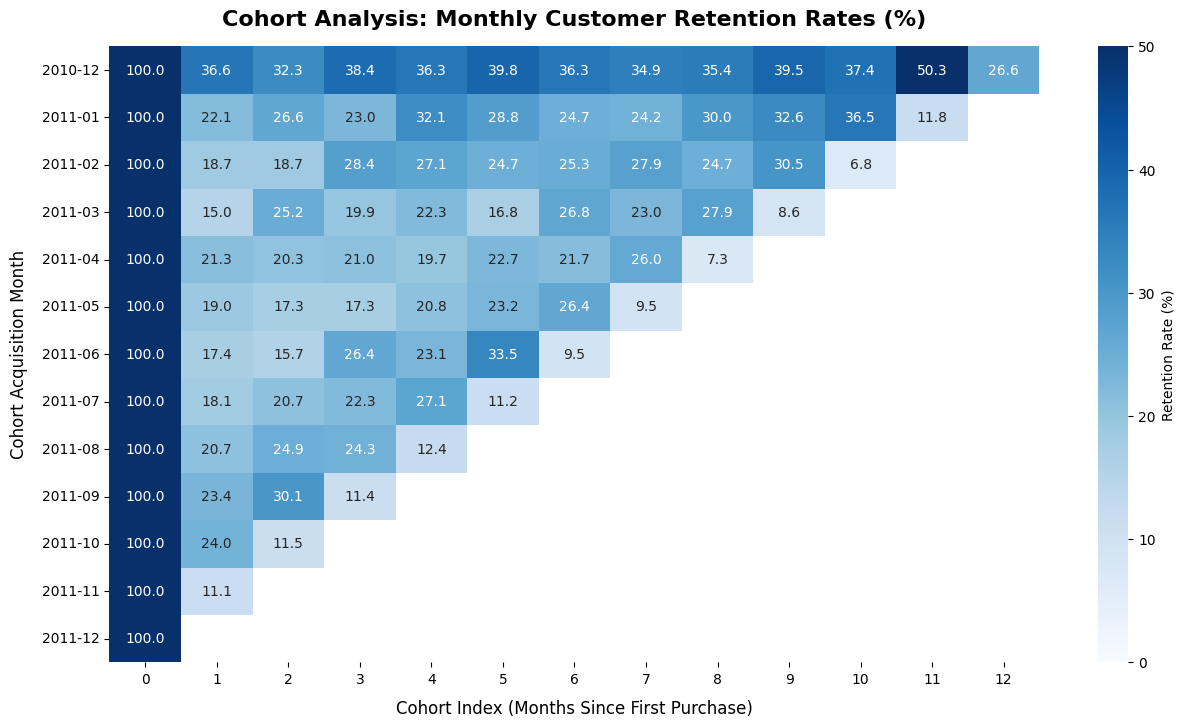

In [ ]:

plt.figure(figsize=(15, 8))
plt.title('Cohort Analysis: Monthly Customer Retention Rates (%)', fontsize=16, fontweight='bold', pad=15)

sns.heatmap(
    data=retention_matrix,
    annot=True,
    fmt='.1f',
    cmap='Blues',
    vmin=0.0,
    vmax=50.0,
    cbar_kws={'label': 'Retention Rate (%)'}
)

plt.xlabel('Cohort Index (Months Since First Purchase)', fontsize=12, labelpad=10)
plt.ylabel('Cohort Acquisition Month', fontsize=12, labelpad=10)
plt.yticks(rotation=0)
plt.show()

<Figure size 1400x600 with 0 Axes>

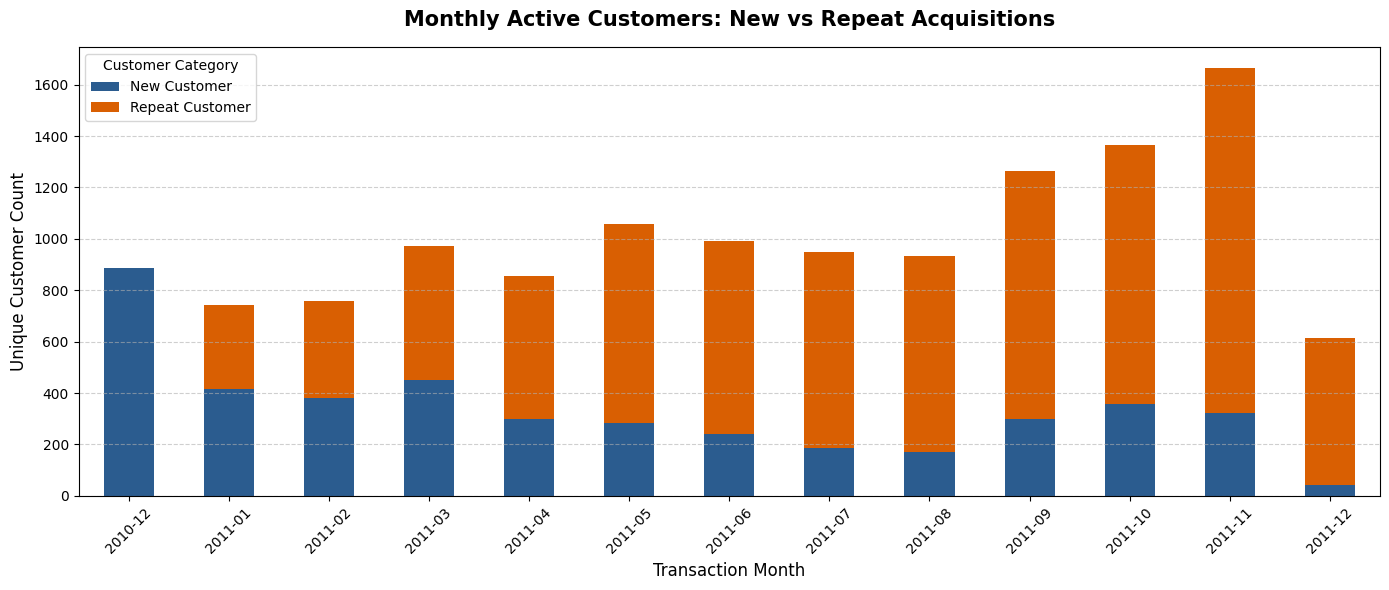

In [ ]:

df_clean['CustomerType'] = np.where(df_clean['CohortIndex'] == 0, 'New Customer', 'Repeat Customer')

monthly_customers = df_clean.groupby(['InvoiceMonth', 'CustomerType'])['CustomerID'].nunique().unstack().fillna(0)
monthly_customers.index = monthly_customers.index.strftime('%Y-%m')

plt.figure(figsize=(14, 6))
monthly_customers.plot(kind='bar', stacked=True, color=['#2b5c8f', '#d95f02'], figsize=(14, 6))

plt.title('Monthly Active Customers: New vs Repeat Acquisitions', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Transaction Month', fontsize=12)
plt.ylabel('Unique Customer Count', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend(title='Customer Category', frameon=True)
plt.tight_layout()
plt.show()

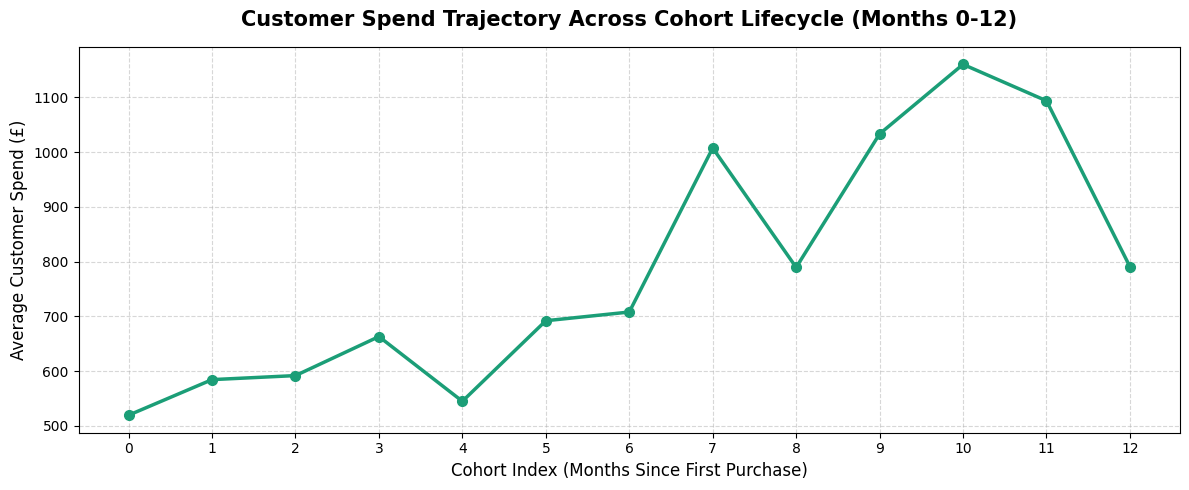

In [ ]:

customer_spend = df_clean.groupby(['CohortIndex', 'CustomerID'])['TotalSpend'].sum().reset_index()


avg_cohort_spend = customer_spend.groupby('CohortIndex')['TotalSpend'].mean()

plt.figure(figsize=(12, 5))
plt.plot(avg_cohort_spend.index, avg_cohort_spend.values, marker='o', linewidth=2.5, color='#1b9e77', markersize=7)

plt.title('Customer Spend Trajectory Across Cohort Lifecycle (Months 0-12)', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Cohort Index (Months Since First Purchase)', fontsize=12)
plt.ylabel('Average Customer Spend (£)', fontsize=12)
plt.xticks(range(0, 13))
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Key Project Findings & Business Insights
1. **Initial Churn Drop:** Most customer cohorts experience the steepest drop-off after Month 0, with Month 1 retention hovering around 18% - 24%.
2. **End-of-Year Re-engagement:** Cohorts from early 2011 show noticeable re-engagement spikes around Month 10-11, corresponding to the Q4 holiday shopping surge (November/December).
3. **Repeat Customer Value:** As seen in the spend trajectory, customers who return in subsequent months (Cohort Index > 0) tend to have a higher average spend per customer compared to their initial trial month.